In [1]:
import warnings
warnings.filterwarnings('ignore')

import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import cmocean.cm as cmo
import numpy as np

from utils import make_map, subplots_structure, get_shelf_edge

In [2]:
timerange = [pd.to_datetime('2022-03-01'), 
             pd.to_datetime('2022-04-01')]

zoomed_extent= [-45, -39, -27, -22]

In [3]:
bathy = xr.open_dataset('../data/gebco_2019.nc')
# rename variables for a padronization
bathy = bathy.rename({'elevation': 'depth'})
bathy = bathy.where(bathy['depth'] < 0, drop=True)

# regional selection (for both dataset loaded)
lon_lower, lon_upper = zoomed_extent[0], zoomed_extent[1] #-50, -40
lat_lower, lat_upper = zoomed_extent[2], zoomed_extent[3] #-29, -23

# bathymetry
bathy = bathy.sel(lon=slice(lon_lower, lon_upper),
                lat=slice(lat_lower, lat_upper))

# lagrangian releasing points
north = [-40, -22]
east = [-39, -26.5]

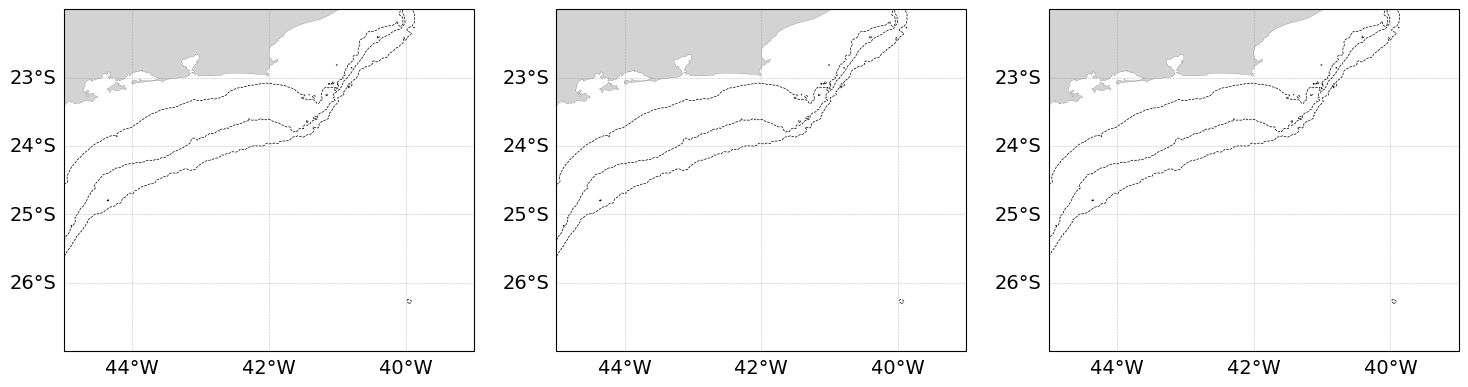

In [4]:
fig,axes = subplots_structure(3, 1, (18,12), 3)

for ax in axes:
    ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1)
    ax.set_extent(zoomed_extent)

    cr = bathy.depth.plot.contour(ax=ax,
                         levels=[-100, -200, -1000], 
                         colors=('k'), linewidths=(0.5), linestyles=('--'))

fig.patch.set_alpha(1.0)
plt.savefig('../figures/manuscript/00_manuscript_schematic_base.png', bbox_inches="tight", dpi=300)

On inkscape:

- add each field scenario
- add processes and citations, if necessary

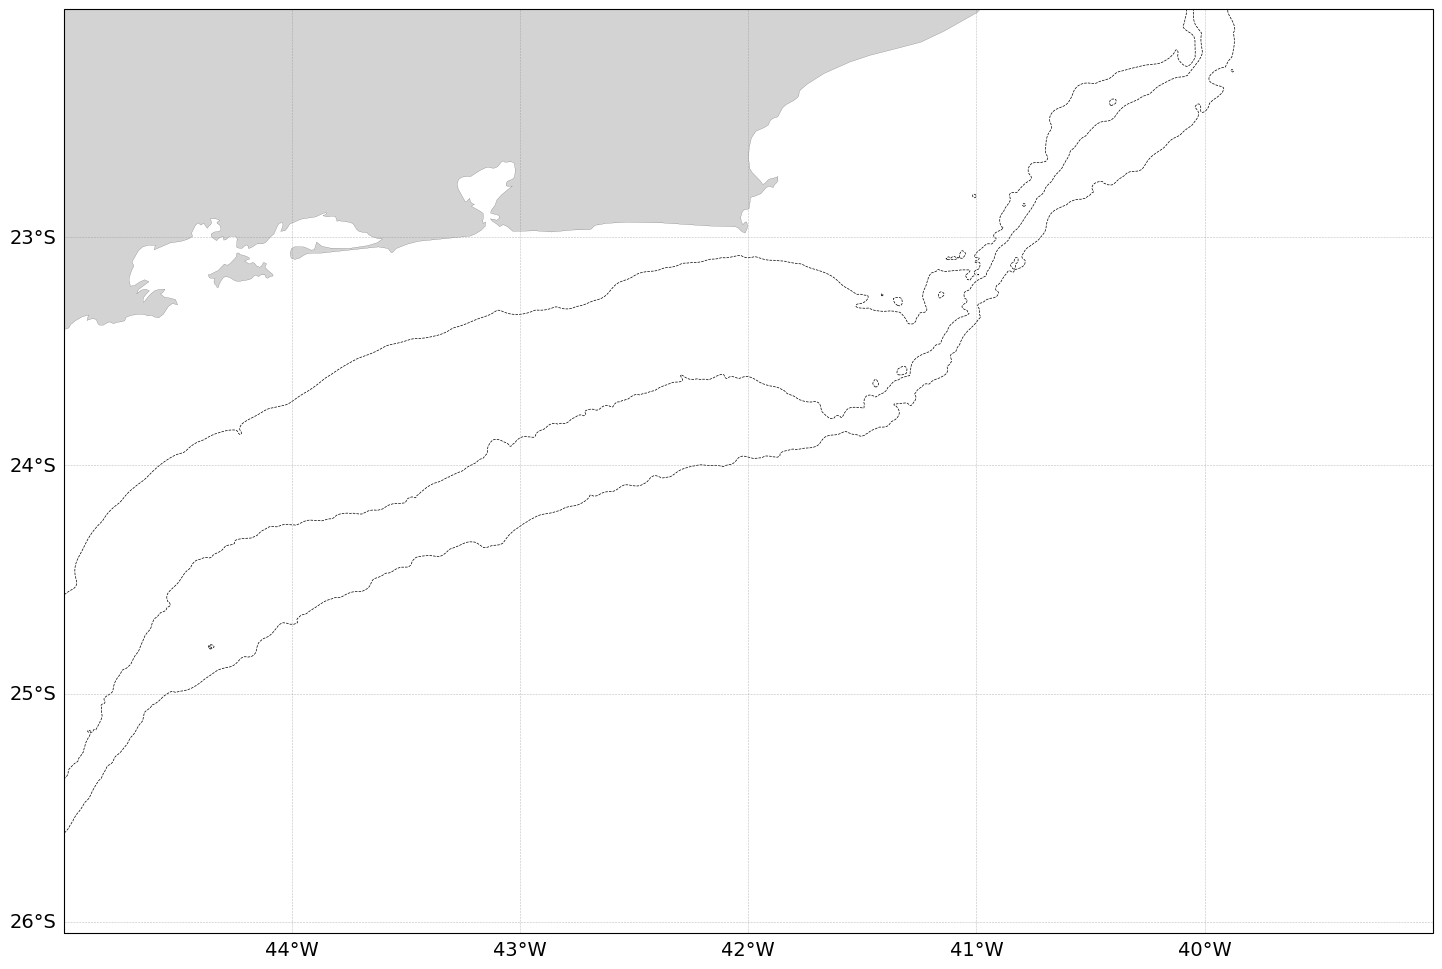

In [5]:
zoomed_extent= [-45, -39, -26.05, -22]

fig,axes = subplots_structure(1, 1, (18,12), 1)

for ax in axes:
    ax = make_map(ax=ax, facecolor='lightgray', deltax=1, deltay=1)
    ax.set_extent(zoomed_extent)

    cr = bathy.depth.plot.contour(ax=ax,
                         levels=[-100, -200, -1000], 
                         colors=('k'), linewidths=(0.5), linestyles=('--'))

fig.patch.set_alpha(1.0)
plt.savefig('../figures/manuscript/00_manuscript_schematic_base_new.png', bbox_inches="tight", dpi=300)